# Лабораторная работа №2. Разработка свёрточной нейронной сети с использованием PyTorch

**Автор, группа:** Сычёв Егор Андреевич, 3825сФИ1.

**Цель:** разработать собственную CNN и обучить её классифицировать изображения CIFAR-10. Архитектура описана собственными классами из базовых слоёв PyTorch; готовые модели и предобученные веса не используются. `torchvision` используется только для загрузки данных.

В работе приведены подготовка данных, описание сети, обучение, ошибка и точность на train после каждой эпохи, графики и итоговые результаты на test. Контрольная выборка validation выделяется из исходной обучающей части и используется для выбора эпохи; test используется только после обучения.

**Запуск:** установить зависимости из `requirements.txt`, открыть ноутбук и выполнить Restart Kernel and Run All Cells. Для воспроизведения полного эксперимента рекомендуется CUDA GPU. На CPU код также работает, но обучение занимает больше времени. Данные сохраняются в `data/`, лучшая модель — в `best_model.pt`.

## 1. Теоретические сведения

Свёртка применяет общие обучаемые фильтры ко всем пространственным положениям изображения. В отличие от полносвязного слоя, она учитывает локальное соседство и использует меньше параметров. Для ядра 3×3, stride=1 и padding=1 размер изображения сохраняется. MaxPool2d(2) уменьшает высоту и ширину вдвое.

В сети используются ReLU, BatchNorm2d и остаточные связи $h\leftarrow h+F(h)$, облегчающие прохождение градиента. AdaptiveAvgPool2d усредняет признаки по пространственным координатам; линейный слой выдаёт 10 логитов.

Используем **прямую формулу softmax без вычитания максимума**, согласно принятому ограничению:
$$p_{ij}=\frac{e^{z_{ij}}}{\sum_{k=1}^{10}e^{z_{ik}}},\qquad
L=-\frac1B\sum_{i=1}^B\log p_{i,y_i}.$$
В коде `NLLLoss` получает `log(p)`, что даёт обычную кросс-энтропию. Повторный softmax не применяется. Предсказание — индекс максимального логита, совпадающий с индексом максимальной вероятности.

Градиенты вычисляются PyTorch autograd; оптимизатор AdamW обновляет веса с отдельной регуляризацией weight decay. Скорость обучения плавно уменьшается косинусным расписанием. Accuracy — доля правильных ответов, ошибка классификации — $1-accuracy$. Кросс-энтропия и ошибка классификации являются разными метриками.

In [1]:
import os, sys, time, random, json, platform
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.datasets import CIFAR10
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('Система:', platform.platform(), '| Устройство:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
plt.rcParams.update({'figure.dpi': 110})

Python: 3.11.18 | PyTorch: 2.11.0+cu128
Система: Windows-10-10.0.26200-SP0 | Устройство: cuda
GPU: NVIDIA GeForce RTX 5090


## 2. Данные и разбиение

[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) содержит 50 000 обучающих и 10 000 тестовых RGB-изображений 32×32, по 10 классам. Из train выделяем по 500 изображений каждого класса для validation: получаем 45 000 / 5 000 / 10 000 объектов.

Пиксели переводятся в float32 [0,1] и нормируются средним и стандартным отклонением каналов, вычисленными **только на 45 000 обучающих объектах**. Во время обучения используем случайное горизонтальное отражение и случайный crop 32×32 после отражающего дополнения на 4 пикселя. Для оценки train, validation и test аугментации отключены.

Среднее каналов: [0.49183995 0.4825412  0.44681957]
Стандартное отклонение: [0.24705073 0.24354212 0.26169223]
Train: N=45000, X=(45000, 3, 32, 32), изображение=(3, 32, 32), метки=(45000,), одна метка=(), dtype=torch.int64
Validation: N=5000, X=(5000, 3, 32, 32), изображение=(3, 32, 32), метки=(5000,), одна метка=(), dtype=torch.int64
Test: N=10000, X=(10000, 3, 32, 32), изображение=(3, 32, 32), метки=(10000,), одна метка=(), dtype=torch.int64
Исходное изображение HWC: (32, 32, 3)


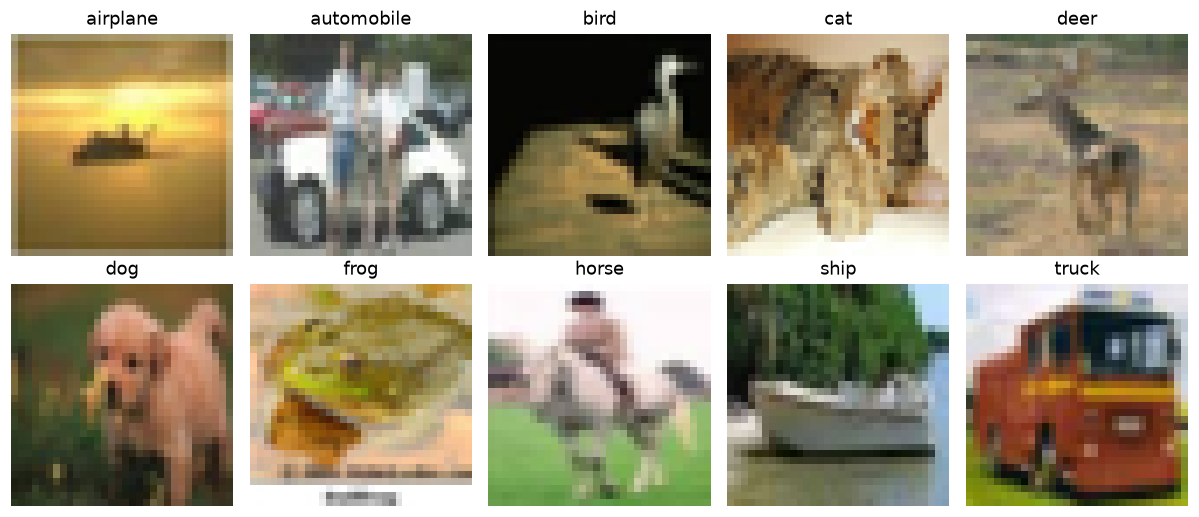

In [2]:
# Текущий адрес официального сервера; MD5 проверяет загрузчик torchvision.
CIFAR10.url = 'https://cave.cs.toronto.edu/kriz/cifar-10-python.tar.gz'
train_source = CIFAR10(root='data', train=True, download=True)
test_source = CIFAR10(root='data', train=False, download=True)
classes = train_source.classes
all_labels = np.asarray(train_source.targets)
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for label in range(10):
    indices = rng.permutation(np.flatnonzero(all_labels == label))
    val_idx.extend(indices[:500])
    train_idx.extend(indices[500:])
train_idx, val_idx = np.array(train_idx), np.array(val_idx)
assert len(set(train_idx) & set(val_idx)) == 0
assert len(train_idx) + len(val_idx) == 50000

def image_tensor(images):
    return torch.from_numpy(np.ascontiguousarray(images.transpose(0, 3, 1, 2))).to(device)

# Храним изображения в uint8; на GPU весь набор занимает менее 200 МБ.
# Это устраняет зависимость от multiprocessing DataLoader в Windows/Jupyter.
X_train = image_tensor(train_source.data[train_idx])
y_train = torch.tensor(all_labels[train_idx], dtype=torch.long, device=device)
X_val = image_tensor(train_source.data[val_idx])
y_val = torch.tensor(all_labels[val_idx], dtype=torch.long, device=device)
X_test = image_tensor(test_source.data)
y_test = torch.tensor(test_source.targets, dtype=torch.long, device=device)

channel_sum = torch.zeros(3, device=device, dtype=torch.float64)
channel_sq_sum = torch.zeros_like(channel_sum)
for start in range(0, len(X_train), 1000):
    chunk = X_train[start:start+1000].to(torch.float64) / 255
    channel_sum += chunk.sum((0, 2, 3))
    channel_sq_sum += chunk.square().sum((0, 2, 3))
count = len(X_train) * 32 * 32
mean = (channel_sum / count).float().reshape(1, 3, 1, 1)
std = (channel_sq_sum / count - (channel_sum / count).square()).sqrt().float().reshape(1, 3, 1, 1)
print('Среднее каналов:', mean.flatten().cpu().numpy())
print('Стандартное отклонение:', std.flatten().cpu().numpy())
for name, X, y in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    print(f'{name}: N={len(X)}, X={tuple(X.shape)}, изображение={tuple(X[0].shape)}, '
          f'метки={tuple(y.shape)}, одна метка={tuple(y[0].shape)}, dtype={y.dtype}')
print('Исходное изображение HWC:', train_source.data[0].shape)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for label, ax in enumerate(axes.flat):
    idx = train_idx[np.flatnonzero(all_labels[train_idx] == label)[0]]
    ax.imshow(train_source.data[idx])
    ax.set_title(classes[label])
    ax.axis('off')
fig.tight_layout()
plt.show()

In [3]:
def prepare_batch(images, augment=False):
    x = images.float() / 255.0
    if augment:
        x = nn.functional.pad(x, (4, 4, 4, 4), mode='reflect')
        b = len(x)
        rows = torch.randint(0, 9, (b, 1, 1), device=device) + torch.arange(32, device=device)[None, :, None]
        cols = torch.randint(0, 9, (b, 1, 1), device=device) + torch.arange(32, device=device)[None, None, :]
        # Независимое случайное смещение для каждого изображения.
        x = x.permute(0, 2, 3, 1)[torch.arange(b, device=device)[:, None, None], rows, cols]
        x = x.permute(0, 3, 1, 2).contiguous()
        flip = torch.rand(b, 1, 1, 1, device=device) < 0.5
        x = torch.where(flip, x.flip(-1), x)
    return ((x - mean) / std).contiguous(memory_format=torch.channels_last)

sample = prepare_batch(X_train[:8], augment=True)
assert sample.shape == (8, 3, 32, 32) and torch.isfinite(sample).all()
print('Размер аугментированной пачки:', tuple(sample.shape))

Размер аугментированной пачки: (8, 3, 32, 32)


## 3. Собственная архитектура

| Этап | Операции | Размер выхода без batch |
|---|---|---|
| Начальный блок | Conv3×3, BN, ReLU | 32×32×32 |
| Блок 1 | Conv3×3, BN, ReLU, MaxPool2 | 64×16×16 |
| Остаточный блок 1 | Две Conv3×3 с BN/ReLU + вход | 64×16×16 |
| Блок 2 | Conv3×3, BN, ReLU, MaxPool2 | 128×8×8 |
| Блок 3 | Conv3×3, BN, ReLU, MaxPool2 | 256×4×4 |
| Остаточный блок 2 | Две Conv3×3 с BN/ReLU + вход | 256×4×4 |
| Классификатор | Global Average Pool, Dropout(0.2), Linear | 10 |

Формат размеров в таблице: C×H×W. Остаточные блоки не меняют число каналов, поэтому вход и результат можно сложить без проекции. Dropout и weight decay уменьшают переобучение. Сеть обучается с нуля.

In [4]:
class ConvBlock(nn.Sequential):
    def __init__(self, in_channels, out_channels, pool=False):
        layers = [nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
                  nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True)]
        if pool:
            layers.append(nn.MaxPool2d(2))
        super().__init__(*layers)

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.branch = nn.Sequential(ConvBlock(channels, channels), ConvBlock(channels, channels))
    def forward(self, x):
        return x + self.branch(x)

class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32), ConvBlock(32, 64, pool=True), ResidualBlock(64),
            ConvBlock(64, 128, pool=True), ConvBlock(128, 256, pool=True), ResidualBlock(256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.2), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

model = CifarCNN().to(device, memory_format=torch.channels_last)
print(model)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Обучаемых параметров:', f'{parameter_count:,}')

def ordinary_softmax(logits):
    exponentials = torch.exp(logits)
    return exponentials / exponentials.sum(dim=1, keepdim=True)

criterion = nn.NLLLoss()
def classification_loss(logits, labels):
    return criterion(torch.log(ordinary_softmax(logits)), labels)

model.eval()
with torch.no_grad():
    logits = model(prepare_batch(X_train[:8]))
    probabilities = ordinary_softmax(logits)
assert logits.shape == (8, 10)
assert torch.allclose(probabilities.sum(1), torch.ones(8, device=device), atol=1e-6)
print('Форма выхода:', tuple(logits.shape), '| Проверка вероятностей пройдена.')

CifarCNN(
  (features): Sequential(
    (0): ConvBlock(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): ConvBlock(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ResidualBlock(
      (branch): Sequential(
        (0): ConvBlock(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvBlock(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1

## 4. Обучение и оценка

Гиперпараметры заданы заранее: **40 эпох, batch size 256, AdamW, начальная learning rate 0.003, weight decay 0.0005**. CosineAnnealingLR уменьшает learning rate до 0.00001. Обучение выполняется в float32.

После каждой эпохи сеть переводится в `eval()`: BatchNorm использует накопленные статистики, Dropout отключён. На **всей обучающей выборке без аугментаций** вычисляются точность, ошибка и loss; отдельно оценивается validation. Сохраняем модель с минимальной validation loss, не используя test для выбора эпохи. Время эпохи включает обе оценки. Запись в `training_progress.txt` позволяет наблюдать запуск снаружи ноутбука.

In [5]:
BATCH_SIZE, EPOCHS = 256, 40
LEARNING_RATE, WEIGHT_DECAY = 0.003, 0.0005
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

@torch.no_grad()
def evaluate(images, labels):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)
    predictions = []
    for start in range(0, len(images), BATCH_SIZE):
        y = labels[start:start+BATCH_SIZE]
        logits = model(prepare_batch(images[start:start+BATCH_SIZE]))
        loss = classification_loss(logits, y)
        loss_sum += loss * len(y)
        prediction = logits.argmax(1)
        correct += (prediction == y).sum()
        predictions.append(prediction)
    return loss_sum.item() / len(images), correct.item() / len(images), torch.cat(predictions)

history, best_val_loss, best_epoch = [], float('inf'), 0
progress_path = Path('training_progress.txt')
progress_path.write_text('', encoding='utf-8')
training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    lr = optimizer.param_groups[0]['lr']
    model.train()
    order = torch.randperm(len(X_train), device=device)
    for start in range(0, len(order), BATCH_SIZE):
        idx = order[start:start+BATCH_SIZE]
        optimizer.zero_grad(set_to_none=True)
        logits = model(prepare_batch(X_train[idx], augment=True))
        loss = classification_loss(logits, y_train[idx])
        if not torch.isfinite(loss):
            raise RuntimeError('Нечисловая функция потерь; обучение остановлено.')
        loss.backward()
        optimizer.step()
    train_loss, train_acc, _ = evaluate(X_train, y_train)
    val_loss, val_acc, _ = evaluate(X_val, y_val)
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save({'state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
                    'mean': mean.cpu(), 'std': std.cpu(), 'classes': classes,
                    'epoch': epoch, 'val_loss': val_loss, 'val_accuracy': val_acc}, 'best_model.pt')
    scheduler.step()
    seconds = time.perf_counter() - epoch_start
    history.append(dict(epoch=epoch, lr=lr, train_loss=train_loss, train_accuracy=train_acc,
                        train_error=1-train_acc, val_loss=val_loss, val_accuracy=val_acc,
                        val_error=1-val_acc, seconds=seconds))
    line = (f'{epoch:02d}/{EPOCHS}: train loss={train_loss:.4f}, accuracy={train_acc:.2%}, '
            f'error={1-train_acc:.2%}; val loss={val_loss:.4f}, accuracy={val_acc:.2%}; '
            f'lr={lr:.6f}; {seconds:.1f} с')
    print(line, flush=True)
    with progress_path.open('a', encoding='utf-8') as f:
        f.write(line + '\n')
training_seconds = time.perf_counter() - training_start
Path('history.json').write_text(json.dumps(history, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Обучение: {training_seconds/60:.2f} мин. Выбрана эпоха {best_epoch}, val loss={best_val_loss:.4f}')

01/40: train loss=1.2485, accuracy=55.02%, error=44.98%; val loss=1.2507, accuracy=54.48%; lr=0.003000; 3.4 с
02/40: train loss=1.0165, accuracy=63.72%, error=36.28%; val loss=1.0385, accuracy=63.52%; lr=0.002995; 3.2 с
03/40: train loss=0.9710, accuracy=68.54%, error=31.46%; val loss=0.9928, accuracy=68.28%; lr=0.002982; 3.2 с
04/40: train loss=0.7700, accuracy=73.48%, error=26.52%; val loss=0.8066, accuracy=72.50%; lr=0.002959; 3.2 с
05/40: train loss=0.5955, accuracy=79.39%, error=20.61%; val loss=0.6254, accuracy=78.44%; lr=0.002927; 3.2 с
06/40: train loss=0.7136, accuracy=75.18%, error=24.82%; val loss=0.7556, accuracy=73.90%; lr=0.002886; 3.2 с
07/40: train loss=0.4479, accuracy=84.44%, error=15.56%; val loss=0.5082, accuracy=83.06%; lr=0.002837; 3.1 с
08/40: train loss=0.4321, accuracy=84.89%, error=15.11%; val loss=0.5130, accuracy=83.00%; lr=0.002780; 3.2 с
09/40: train loss=0.4902, accuracy=83.70%, error=16.30%; val loss=0.5912, accuracy=81.12%; lr=0.002714; 3.1 с
10/40: tra

## 5. Оценка лучшей модели на тестовой выборке

In [6]:
checkpoint = torch.load('best_model.pt', map_location=device, weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
test_loss, test_accuracy, test_pred = evaluate(X_test, y_test)
selected_train_loss, selected_train_accuracy, _ = evaluate(X_train, y_train)
test_error = 1 - test_accuracy
print('Выбранная эпоха:', checkpoint['epoch'])
print(f'Train выбранной модели: accuracy={selected_train_accuracy:.2%}, error={1-selected_train_accuracy:.2%}')
print(f'Test: loss={test_loss:.4f}, accuracy={test_accuracy:.2%}, error={test_error:.2%}')
print('Ошибочных ответов:', int((test_pred != y_test).sum()), 'из', len(y_test))
assert np.isfinite(test_loss)
results = dict(test_accuracy=test_accuracy, test_error=test_error, test_loss=test_loss,
               best_epoch=best_epoch, training_seconds=training_seconds,
               selected_train_accuracy=selected_train_accuracy, parameters=parameter_count)
Path('results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')

Выбранная эпоха: 34
Train выбранной модели: accuracy=99.56%, error=0.44%
Test: loss=0.3832, accuracy=90.72%, error=9.28%
Ошибочных ответов: 928 из 10000


224

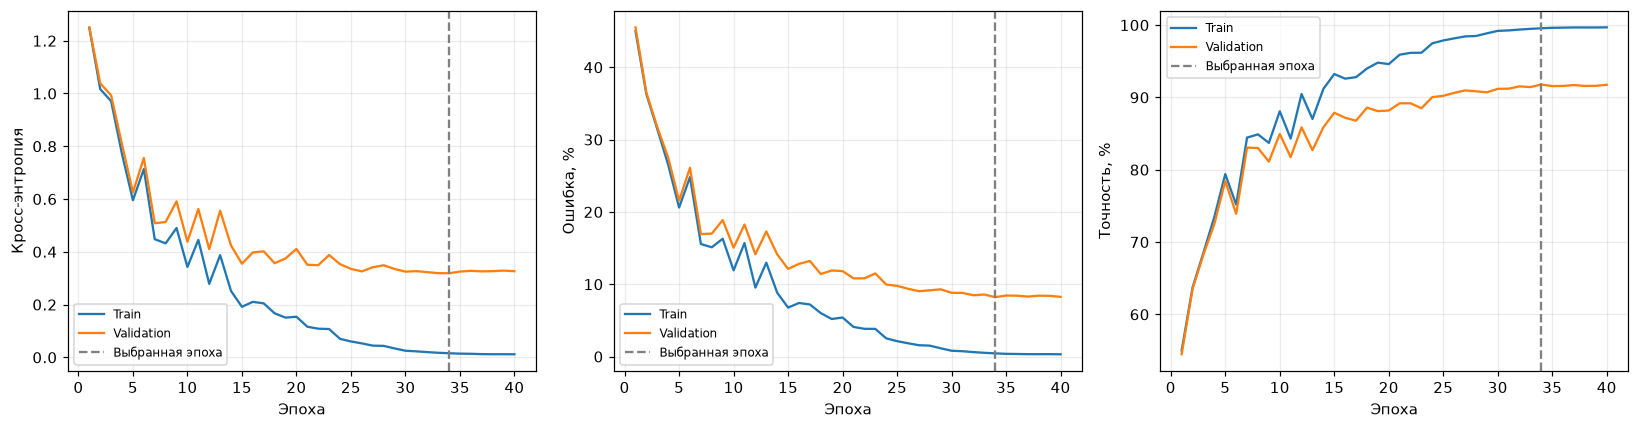

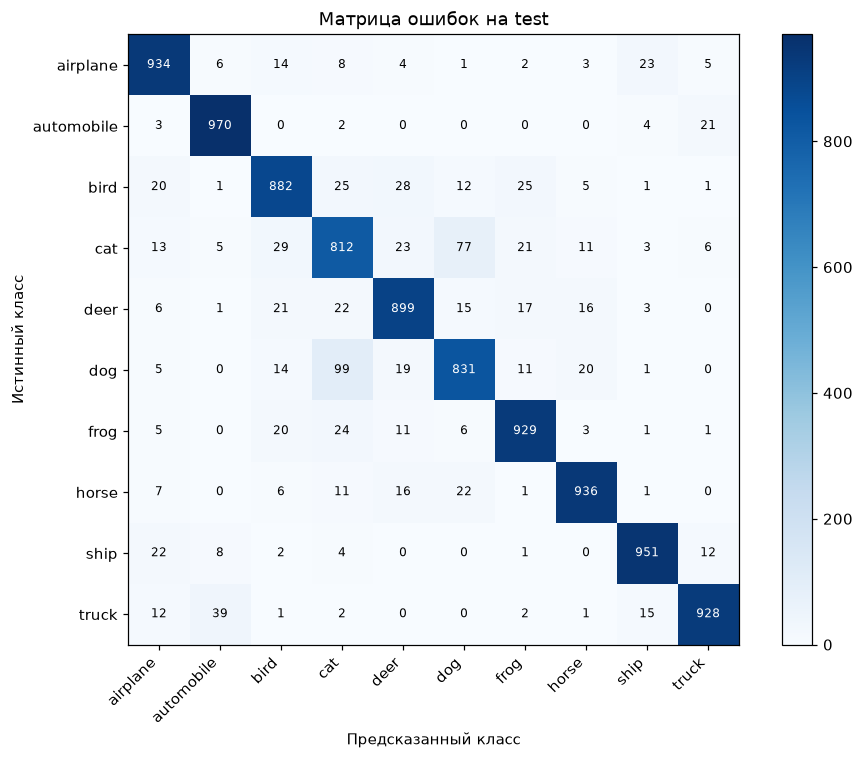

Точность по классам (recall):
airplane  : 93.40% (934/1000)
automobile: 97.00% (970/1000)
bird      : 88.20% (882/1000)
cat       : 81.20% (812/1000)
deer      : 89.90% (899/1000)
dog       : 83.10% (831/1000)
frog      : 92.90% (929/1000)
horse     : 93.60% (936/1000)
ship      : 95.10% (951/1000)
truck     : 92.80% (928/1000)


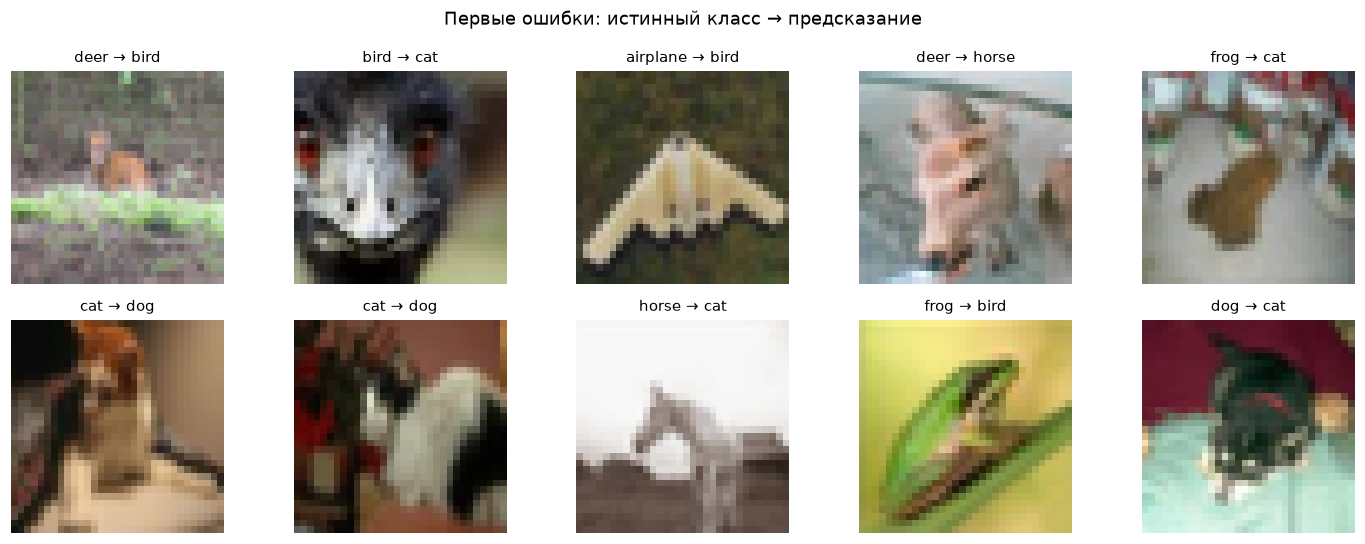

In [7]:
epochs = [h['epoch'] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for prefix, label in [('train', 'Train'), ('val', 'Validation')]:
    axes[0].plot(epochs, [h[f'{prefix}_loss'] for h in history], label=label)
    axes[1].plot(epochs, [h[f'{prefix}_error'] * 100 for h in history], label=label)
    axes[2].plot(epochs, [h[f'{prefix}_accuracy'] * 100 for h in history], label=label)
for ax, ylabel in zip(axes, ['Кросс-энтропия', 'Ошибка, %', 'Точность, %']):
    ax.axvline(best_epoch, color='gray', linestyle='--', label='Выбранная эпоха')
    ax.set(xlabel='Эпоха', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

true = y_test.cpu().numpy()
predicted = test_pred.cpu().numpy()
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (true, predicted), 1)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(confusion[i, j]), ha='center', va='center', fontsize=8,
                color='white' if confusion[i, j] > confusion.max()/2 else 'black')
ax.set(xticks=range(10), yticks=range(10), xticklabels=classes, yticklabels=classes,
       xlabel='Предсказанный класс', ylabel='Истинный класс', title='Матрица ошибок на test')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()
print('Точность по классам (recall):')
for name, correct, total in zip(classes, confusion.diagonal(), confusion.sum(1)):
    print(f'{name:10}: {correct/total:.2%} ({correct}/{total})')

errors = np.flatnonzero(true != predicted)
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for ax, idx in zip(axes.flat, errors[:10]):
    ax.imshow(test_source.data[idx])
    ax.set_title(f'{classes[true[idx]]} → {classes[predicted[idx]]}', fontsize=10)
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Первые ошибки: истинный класс → предсказание')
fig.tight_layout()
plt.show()

In [11]:
display(Markdown(f"""
## 6. Выводы

Разработана собственная свёрточная сеть из базовых слоёв PyTorch с **{parameter_count:,}** обучаемыми параметрами. Использованы остаточные связи, нормализация, аугментации, dropout и weight decay. Готовые архитектуры и веса не использовались.

Обучение выполнено на 45 000 изображений, выбор эпохи — на 5 000 validation-изображений. За 40 эпох обучение с оценкой train и validation заняло **{training_seconds/60:.2f} мин** на указанном выше устройстве. По минимальной validation loss выбрана **эпоха {best_epoch}**.

На независимых 10 000 тестовых изображениях получены **точность {test_accuracy:.2%}**, **ошибка {test_error:.2%}**, кросс-энтропия **{test_loss:.4f}**. Точность выбранной модели на train равна **{selected_train_accuracy:.2%}**; разрыв с test составляет **{(selected_train_accuracy-test_accuracy)*100:.2f} процентного пункта** и характеризует разницу между запоминанием обучающих данных и обобщением.

Графики показывают ход оптимизации и позволяют выявлять переобучение. Матрица ошибок и примеры неверных ответов позволяют исследовать путаницу визуально похожих классов. Для дальнейшего улучшения можно отдельно исследовать более длительное обучение и более широкую сеть, оценивая варианты только по validation.

"""))


## 6. Выводы

Разработана собственная свёрточная сеть из базовых слоёв PyTorch с **1,646,122** обучаемыми параметрами. Использованы остаточные связи, нормализация, аугментации, dropout и weight decay. Готовые архитектуры и веса не использовались.

Обучение выполнено на 45 000 изображений, выбор эпохи — на 5 000 validation-изображений. За 40 эпох обучение с оценкой train и validation заняло **2.11 мин** на указанном выше устройстве. По минимальной validation loss выбрана **эпоха 34**.

На независимых 10 000 тестовых изображениях получены **точность 90.72%**, **ошибка 9.28%**, кросс-энтропия **0.3832**. Точность выбранной модели на train равна **99.56%**; разрыв с test составляет **8.84 процентного пункта** и характеризует разницу между запоминанием обучающих данных и обобщением.

Графики показывают ход оптимизации и позволяют выявлять переобучение. Матрица ошибок и примеры неверных ответов позволяют исследовать путаницу визуально похожих классов. Для дальнейшего улучшения можно отдельно исследовать более длительное обучение и более широкую сеть, оценивая варианты только по validation.

